<a href="https://colab.research.google.com/github/Michruiz2710/skin-cancer-detection-APPR/blob/main/notebooks/03_entrenamiento_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 · Entrenamiento v2 — DenseNet201 con Mejoras

**Proyecto APPR — Detección de Cáncer de Piel**

Este notebook implementa las correcciones al entrenamiento original:

| # | Mejora | Problema que resuelve |
|---|---|---|
| 1 | Balanceo real (~2000 imágenes/clase) | Desbalanceo 58:1 |
| 2 | Focal Loss + class weights | Clases minoritarias ignoradas |
| 3 | Dense(512, ReLU) en la cabeza | Salto brusco 1920→7 |
| 4 | lr=1e-4 fase 1, lr=1e-5 fase 2 | LR demasiado alto destruía pesos |
| 5 | Más épocas (20+30) | Poco tiempo de aprendizaje |

## 1 · Configuración del entorno

In [ ]:
import os
from google.colab import drive

# Desmontar de forma segura si existiera un montaje previo roto o residual
!usr/bin/fusermount -u /content/drive 2>/dev/null || true

# Si la carpeta existe y contiene archivos locales creados por error, la limpiamos
if os.path.exists('/content/drive') and os.listdir('/content/drive'):
    print("Limpiando directorio residual...")
    !rm -rf /content/drive

# Volver a intentar el montaje
drive.mount('/content/drive', force_remount=True)

Limpiando directorio residual...
Mounted at /content/drive


In [ ]:
# Instalar dependencias necesarias
!pip install -q datasets
print('✅ Librería datasets instalada')

✅ Librería datasets instalada


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.applications import DenseNet201
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from sklearn.utils.class_weight import compute_class_weight
import warnings
warnings.filterwarnings('ignore')

# Semilla para reproducibilidad
tf.random.set_seed(42)
np.random.seed(42)

print('TensorFlow:', tf.__version__)
print('GPU disponible:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2 · Rutas y configuración

In [ ]:
# ── RUTAS ─────────────────────────────────────────────────────────────────────
DRIVE_BASE = '/content/drive/MyDrive/skin-cancer-APPR'
MODELS_DIR = os.path.join(DRIVE_BASE, 'models')
os.makedirs(MODELS_DIR, exist_ok=True)

# ── HIPERPARÁMETROS ───────────────────────────────────────────────────────────
IMG_SIZE         = 224
BATCH_SIZE       = 32
TARGET_PER_CLASS = 2000   # Balanceo real
EPOCHS_PHASE1    = 20     # Base congelada
EPOCHS_PHASE2    = 30     # Fine-tuning
LR_PHASE1        = 1e-4  # Corregido (antes era 1e-3)
LR_PHASE2        = 1e-5
UNFREEZE_LAYERS  = 50    # Capas a descongelar en fase 2
DROPOUT_RATE     = 0.5

# Normalización ImageNet
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

# Mapeo de clases (abreviaciones HAM10000)
CLASS_NAMES = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
CLASS_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)

# Mapeo de nombres completos HuggingFace → abreviaciones HAM10000
HF_TO_SHORT = {
    'melanocytic_Nevi':              'nv',
    'melanoma':                      'mel',
    'benign_keratosis-like_lesions': 'bkl',
    'basal_cell_carcinoma':          'bcc',
    'actinic_keratoses':             'akiec',
    'vascular_lesions':              'vasc',
    'dermatofibroma':                'df',
}

print('Configuración:')
print(f'  Imágenes objetivo por clase : {TARGET_PER_CLASS}')
print(f'  Épocas Fase 1 (congelado)   : {EPOCHS_PHASE1}  lr={LR_PHASE1}')
print(f'  Épocas Fase 2 (fine-tuning) : {EPOCHS_PHASE2}  lr={LR_PHASE2}')
print(f'  Batch size                  : {BATCH_SIZE}')
print(f'  Modelos → {MODELS_DIR}')

Configuración:
  Imágenes objetivo por clase : 2000
  Épocas Fase 1 (congelado)   : 20  lr=0.0001
  Épocas Fase 2 (fine-tuning) : 30  lr=1e-05
  Batch size                  : 32
  Modelos → /content/drive/MyDrive/skin-cancer-APPR/models


## 3 · Carga del dataset y conversión a numpy (una sola vez)

Descargamos desde HuggingFace y convertimos todas las imágenes a arrays numpy
redimensionados (224×224), guardándolos en archivos `.npy` en Drive.
**Esto se hace una sola vez** (~5 min). En ejecuciones siguientes se cargan
directamente desde Drive en segundos.

In [ ]:
from datasets import load_dataset
from PIL import Image as PILImage

MEAN_NP = np.array(MEAN, dtype=np.float32)
STD_NP  = np.array(STD,  dtype=np.float32)

DATA_DIR = os.path.join(DRIVE_BASE, 'data')
os.makedirs(DATA_DIR, exist_ok=True)

def convert_and_save(split):
    """
    Convierte un split de HuggingFace a arrays numpy normalizados
    y los guarda en Drive. Si ya existen, los carga directamente.
    """
    x_path = os.path.join(DATA_DIR, f'{split}_X.npy')
    y_path = os.path.join(DATA_DIR, f'{split}_y.npy')

    if os.path.exists(x_path) and os.path.exists(y_path):
        print(f'[{split}] Cargando desde Drive...', end=' ')
        X = np.load(x_path)
        y = np.load(y_path)
        print(f'{len(X)} imágenes ✅')
        return X, y

    print(f'[{split}] Convirtiendo desde HuggingFace...')
    hf_split = hf_ds[split]
    n = len(hf_split)
    X = np.zeros((n, IMG_SIZE, IMG_SIZE, 3), dtype=np.float32)
    y = np.zeros(n, dtype=np.int32)

    for i in range(n):
        sample = hf_split[i]
        img = sample['image'].convert('RGB').resize((IMG_SIZE, IMG_SIZE), PILImage.BILINEAR)
        arr = np.array(img, dtype=np.float32) / 255.0
        X[i] = (arr - MEAN_NP) / STD_NP
        y[i] = CLASS_INDEX[HF_TO_SHORT.get(sample['dx'], sample['dx'])]
        if (i + 1) % 500 == 0:
            print(f'  {i+1}/{n}...')

    np.save(x_path, X)
    np.save(y_path, y)
    print(f'  Guardado en Drive ✅  shape: {X.shape}')
    return X, y

# Descargar dataset (metadatos; imágenes se acceden split por split)
print('Cargando metadatos de HuggingFace...')
hf_ds = load_dataset('marmal88/skin_cancer')

# Convertir y guardar cada split
X_train_raw, y_train_raw = convert_and_save('train')
X_val,       y_val       = convert_and_save('validation')
X_test,      y_test      = convert_and_save('test')

print(f'\nTrain : {X_train_raw.shape}')
print(f'Val   : {X_val.shape}')
print(f'Test  : {X_test.shape}')

# DataFrame ligero para el balanceo (solo índices)
df_train_raw = pd.DataFrame({'idx': range(len(y_train_raw)), 'label': y_train_raw})

Cargando metadatos de HuggingFace...


[train] Convirtiendo desde HuggingFace...
  500/9577...
  1000/9577...
  1500/9577...
  2000/9577...
  2500/9577...
  3000/9577...
  3500/9577...
  4000/9577...
  4500/9577...
  5000/9577...
  5500/9577...
  6000/9577...
  6500/9577...
  7000/9577...
  7500/9577...
  8000/9577...
  8500/9577...
  9000/9577...
  9500/9577...
  Guardado en Drive ✅  shape: (9577, 224, 224, 3)
[validation] Convirtiendo desde HuggingFace...
  500/2492...
  1000/2492...
  1500/2492...
  2000/2492...
  Guardado en Drive ✅  shape: (2492, 224, 224, 3)
[test] Convirtiendo desde HuggingFace...
  500/1285...
  1000/1285...
  Guardado en Drive ✅  shape: (1285, 224, 224, 3)

Train : (9577, 224, 224, 3)
Val   : (2492, 224, 224, 3)
Test  : (1285, 224, 224, 3)


In [ ]:
# Balanceo: solo guardamos los ÍNDICES (no copiamos imágenes)
balanced_idx = []
for label_idx in range(NUM_CLASSES):
    idx_class = np.where(y_train_raw == label_idx)[0]
    n_original = len(idx_class)

    if n_original < TARGET_PER_CLASS:
        idx_resampled = resample(idx_class, replace=True,
                                 n_samples=TARGET_PER_CLASS, random_state=42)
        print(f'  {CLASS_NAMES[label_idx]:6s}: {n_original:4d} → {TARGET_PER_CLASS}')
    else:
        idx_resampled = resample(idx_class, replace=False,
                                 n_samples=TARGET_PER_CLASS, random_state=42)
        print(f'  {CLASS_NAMES[label_idx]:6s}: {n_original:4d} → {TARGET_PER_CLASS} (submuestreado)')

    balanced_idx.append(idx_resampled)

balanced_idx = np.concatenate(balanced_idx)
np.random.seed(42)
np.random.shuffle(balanced_idx)
y_train_bal = y_train_raw[balanced_idx]  # solo etiquetas, NO imágenes

# Liberar X_train_raw de RAM — se leerá desde disco en el pipeline
X_train_path = os.path.join(DATA_DIR, 'train_X.npy')
del X_train_raw
import gc; gc.collect()

print(f'\nÍndices balanceados: {len(balanced_idx)}')
print('X_train_raw liberado de RAM ✅')

  akiec :  315 → 2000
  bcc   :  487 → 2000
  bkl   : 1048 → 2000
  df    :  110 → 2000
  mel   : 1076 → 2000
  nv    : 6405 → 2000 (submuestreado)
  vasc  :  136 → 2000

Índices balanceados: 14000
X_train_raw liberado de RAM ✅


## 4 · Pipeline tf.data desde arrays numpy (rápido)

Con los arrays ya en memoria, tf.data los sirve directamente a la GPU
sin cuello de botella de disco. Velocidad esperada: ~500 ms/step.

In [ ]:
# ── Capas de augmentation (se aplican solo durante training=True) ─────────────
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.07),   # ±~25 grados
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.2),
], name='augmentation')

print('Capas de augmentation definidas.')

Capas de augmentation definidas.


In [ ]:
# Pipeline que lee X desde disco por lotes — sin cargar todo en RAM

X_val_path  = os.path.join(DATA_DIR, 'validation_X.npy')
X_test_path = os.path.join(DATA_DIR, 'test_X.npy')

# Cargar val y test completos (son pequeños: ~600 y ~600 imágenes)
X_val_arr  = np.load(X_val_path)
X_test_arr = np.load(X_test_path)

def make_dataset_from_npy(X_path, indices, y, training=False, batch_size=BATCH_SIZE):
    """Lee filas de un .npy en disco usando índices, sin cargar el array completo."""
    X_mmap = np.load(X_path, mmap_mode='r')  # memory-mapped: no carga en RAM
    y_oh = tf.keras.utils.to_categorical(y[indices] if indices is not None else y,
                                          NUM_CLASSES).astype(np.float32)
    idx = indices if indices is not None else np.arange(len(y))

    def gen():
        for i, lbl in zip(idx, y_oh):
            yield X_mmap[i].astype(np.float32), lbl

    ds = tf.data.Dataset.from_generator(
        gen,
        output_signature=(
            tf.TensorSpec(shape=(IMG_SIZE, IMG_SIZE, 3), dtype=tf.float32),
            tf.TensorSpec(shape=(NUM_CLASSES,),          dtype=tf.float32),
        )
    )
    if training:
        ds = ds.shuffle(buffer_size=1000, seed=42)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

def make_dataset_from_array(X, y, training=False, batch_size=BATCH_SIZE):
    y_oh = tf.keras.utils.to_categorical(y, NUM_CLASSES).astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((X, y_oh))
    if training:
        ds = ds.shuffle(buffer_size=len(X), seed=42)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset_from_npy(X_train_path, balanced_idx, y_train_raw, training=True)
val_ds   = make_dataset_from_array(X_val_arr,  y_val,  training=False)
test_ds  = make_dataset_from_array(X_test_arr, y_test, training=False)

print(f'Pasos por época (train): {len(balanced_idx) // BATCH_SIZE}')
print(f'Pasos de validación    : {len(X_val_arr) // BATCH_SIZE}')

Pasos por época (train): 437
Pasos de validación    : 77


## 5 · Focal Loss

**Mejora #2:** La Focal Loss penaliza más los ejemplos difíciles (clases raras mal
clasificadas) y menos los fáciles (nv bien clasificado). El parámetro `gamma=2.0`
es el valor estándar del paper original de Focal Loss (Lin et al., 2017).

In [ ]:
class FocalLoss(tf.keras.losses.Loss):
    """
    Focal Loss para clasificación multi-clase.
    FL(p_t) = -alpha_t * (1 - p_t)^gamma * log(p_t)

    - gamma=2.0  : factor de enfoque (reduce peso a ejemplos fáciles)
    - alpha       : pesos por clase (mismos que class_weights)
    """
    def __init__(self, gamma=2.0, alpha=None, **kwargs):
        super().__init__(**kwargs)
        self.gamma = gamma
        self.alpha = alpha  # Tensor de forma (num_classes,)

    def call(self, y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        p_t = tf.reduce_sum(y_true * y_pred, axis=-1)
        focal_weight = tf.pow(1.0 - p_t, self.gamma)
        ce = -tf.math.log(p_t)
        if self.alpha is not None:
            alpha_t = tf.reduce_sum(y_true * self.alpha, axis=-1)
            loss = alpha_t * focal_weight * ce
        else:
            loss = focal_weight * ce
        return tf.reduce_mean(loss)

# Calcular pesos de clase sobre el train ORIGINAL (sin balancear)
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=df_train_raw['label'].values
)
class_weights_array = class_weights_array / class_weights_array.sum() * NUM_CLASSES

print('Pesos de clase (alpha):')
for i, name in enumerate(CLASS_NAMES):
    print(f'  {name:6s}: {class_weights_array[i]:.3f}')

alpha_tensor  = tf.constant(class_weights_array, dtype=tf.float32)
focal_loss_fn = FocalLoss(gamma=2.0, alpha=alpha_tensor, name='focal_loss')

Pesos de clase (alpha):
  akiec : 0.937
  bcc   : 0.606
  bkl   : 0.282
  df    : 2.684
  mel   : 0.274
  nv    : 0.046
  vasc  : 2.171


## 6 · Construcción del modelo

**Mejora #3:** Añadimos Dense(512, ReLU) entre el GAP y la capa de salida.
Esto da al modelo capacidad para aprender combinaciones no lineales de
las 1920 características de DenseNet antes de clasificar.

In [ ]:
def build_model(trainable_base=False):
    """
    Construye DenseNet201 con cabeza de clasificación mejorada.

    Arquitectura de la cabeza (igual que el paper):
      GAP → Dense(512, ReLU) → Dropout(0.5) → Dense(7, softmax)
    """
    # Base: DenseNet201 preentrenado en ImageNet, sin la cabeza original
    base = DenseNet201(
        weights='imagenet',
        include_top=False,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = trainable_base

    # Entrada con augmentation (solo activo en training=True)
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = data_augmentation(inputs)       # Augmentation durante entrenamiento
    x = base(x, training=trainable_base)

    # Cabeza de clasificación mejorada
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.Dense(512, activation='relu', name='dense_512')(x)  # <- NUEVO
    x = layers.Dropout(DROPOUT_RATE, name='dropout')(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', name='predictions')(x)

    model = Model(inputs=inputs, outputs=outputs, name='DenseNet201_v2')
    return model, base

# Construir modelo para Fase 1 (base congelada)
model, base_model = build_model(trainable_base=False)

print(f'Parámetros totales     : {model.count_params():,}')
print(f'Parámetros entrenables : {sum(p.numpy().size for p in model.trainable_weights):,}')
print(f'Parámetros congelados  : {sum(p.numpy().size for p in model.non_trainable_weights):,}')

74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Parámetros totales     : 19,309,127
Parámetros entrenables : 987,143
Parámetros congelados  : 18,321,984


## 7 · Fase 1 — Cargar modelo ya entrenado desde Drive

La Fase 1 ya fue completada anteriormente (val_accuracy: 20.51%).
Cargamos el mejor modelo guardado directamente desde Drive.

In [ ]:
# Cargar el mejor modelo de Fase 1 guardado en Drive
model = tf.keras.models.load_model(
    os.path.join(MODELS_DIR, 'densenet201_v2_phase1_best.keras'),
    custom_objects={'FocalLoss': FocalLoss}
)
# Recuperar la base de DenseNet para poder descongelar capas en Fase 2
base_model = model.get_layer('densenet201')

print('Modelo Fase 1 cargado ✅')
print(f'Parámetros totales: {model.count_params():,}')
print(f'val_accuracy Fase 1 (ya entrenada): 20.51%')

Modelo Fase 1 cargado ✅
Parámetros totales: 19,309,127
val_accuracy Fase 1 (ya entrenada): 20.51%


## 8 · Fase 2 — Fine-tuning (descongelamos últimas capas)

Ahora descongelamos las últimas 50 capas de DenseNet201 y usamos
`lr=1e-5` (10× más bajo que Fase 1) para ajustar esas capas sin
destruir el conocimiento que ya aprendieron.

In [ ]:
# Descongelar las últimas UNFREEZE_LAYERS capas de la base
base_model.trainable = True

total_layers = len(base_model.layers)
freeze_until = total_layers - UNFREEZE_LAYERS

for i, layer in enumerate(base_model.layers):
    layer.trainable = (i >= freeze_until)

trainable_now = sum(1 for l in base_model.layers if l.trainable)
print(f'Capas totales en base  : {total_layers}')
print(f'Capas descongeladas    : {trainable_now} (últimas {UNFREEZE_LAYERS})')
print(f'Capas congeladas       : {total_layers - trainable_now}')
print(f'\nParámetros entrenables ahora: {sum(p.numpy().size for p in model.trainable_weights):,}')

Capas totales en base  : 707
Capas descongeladas    : 50 (últimas 50)
Capas congeladas       : 657

Parámetros entrenables ahora: 2,878,151


In [ ]:
# Recompilar con LR más bajo para Fase 2
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_PHASE2),
    loss=focal_loss_fn,
    metrics=['accuracy']
)

print('Modelo recompilado para Fase 2:')
print(f'  Optimizer : Adam, lr={LR_PHASE2}')
print(f'  Épocas    : {EPOCHS_PHASE2}')

Modelo recompilado para Fase 2:
  Optimizer : Adam, lr=1e-05
  Épocas    : 30


In [ ]:
# Callbacks Fase 2
callbacks_phase2 = [
    ModelCheckpoint(
        filepath=os.path.join(MODELS_DIR, 'densenet201_v2_phase2_best.keras'),
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=4,
        min_lr=1e-8,
        verbose=1
    ),
    EarlyStopping(
        monitor='val_accuracy',
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

print('Callbacks Fase 2 configurados.')

Callbacks Fase 2 configurados.


In [ ]:
print('=' * 60)
print('FASE 2 — Fine-tuning (últimas 50 capas descongeladas)')
print('=' * 60)

history2 = model.fit(
    train_ds,
    epochs=EPOCHS_PHASE2,
    validation_data=val_ds,
    callbacks=callbacks_phase2,
    verbose=1
)

best_val_acc_p2 = max(history2.history['val_accuracy'])
print(f'\nMejor val_accuracy Fase 2: {best_val_acc_p2:.4f} ({best_val_acc_p2*100:.2f}%)')

FASE 2 — Fine-tuning (últimas 50 capas descongeladas)
Epoch 1/30
    438/Unknown 161s 262ms/step - accuracy: 0.2564 - loss: 0.9710
Epoch 1: val_accuracy improved from None to 0.19623, saving model to /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v2_phase2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v2_phase2_best.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 197s 346ms/step - accuracy: 0.2611 - loss: 0.8747 - val_accuracy: 0.1962 - val_loss: 0.3981 - learning_rate: 1.0000e-05
Epoch 2/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 257ms/step - accuracy: 0.2651 - loss: 0.7957
Epoch 2: val_accuracy improved from 0.19623 to 0.21709, saving model to /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v2_phase2_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v2_phase2_best.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 138s 304ms/step - accuracy: 0.2654 - loss: 0.7913 - val_accuracy: 0.2171

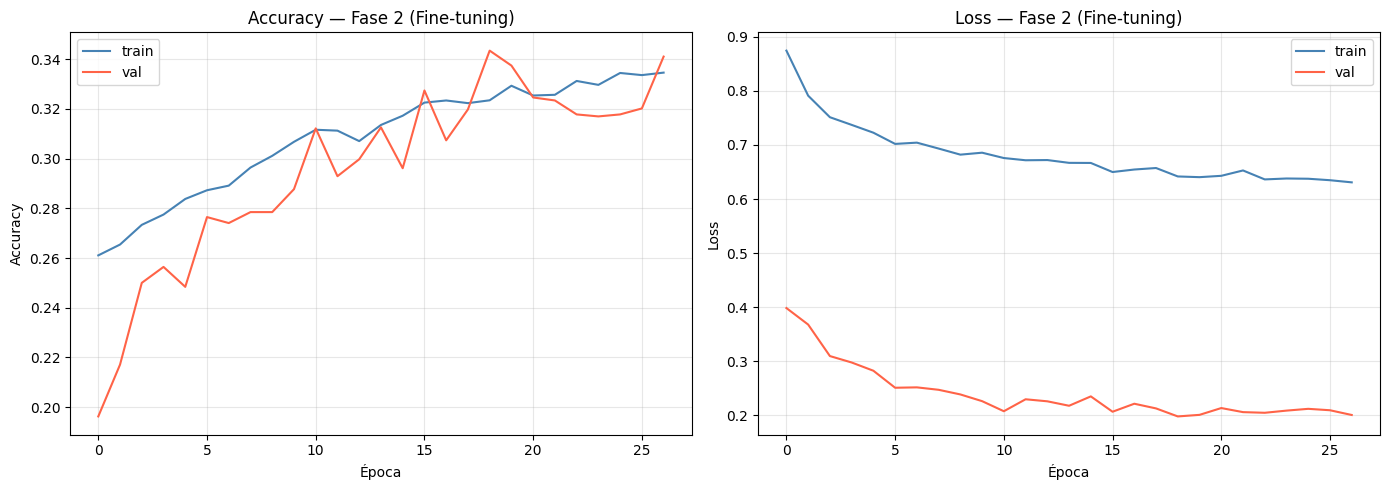

In [ ]:
# Gráfica de Fase 2
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history2.history['accuracy'],     label='train', color='steelblue')
ax1.plot(history2.history['val_accuracy'], label='val',   color='tomato')
ax1.set_title('Accuracy — Fase 2 (Fine-tuning)')
ax1.set_xlabel('Época')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(history2.history['loss'],     label='train', color='steelblue')
ax2.plot(history2.history['val_loss'], label='val',   color='tomato')
ax2.set_title('Loss — Fase 2 (Fine-tuning)')
ax2.set_xlabel('Época')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'fase2_curvas.png'), dpi=150)
plt.show()

## 9 · Curvas combinadas (Fase 1 + Fase 2)

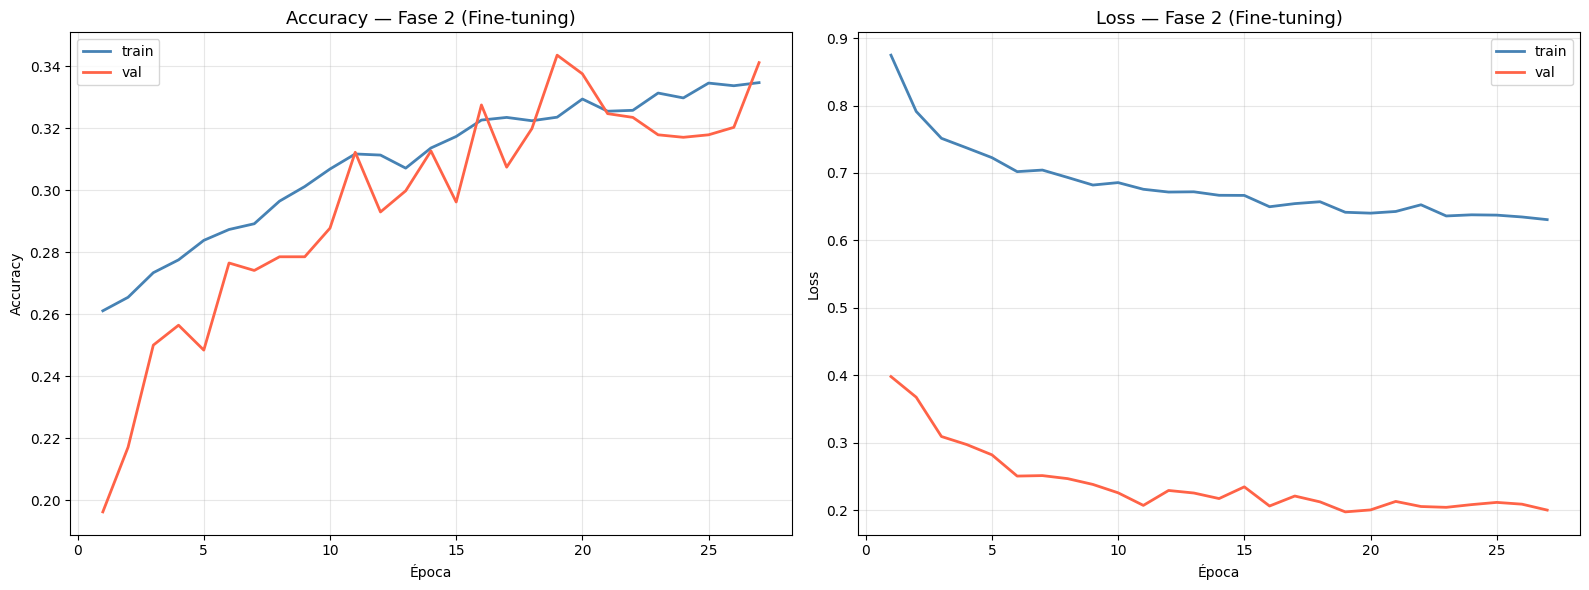

val_accuracy Fase 1 (cargada) : 20.51%
val_accuracy Fase 2 (mejor)   : 34.35%


In [ ]:
# Curvas de Fase 2
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

epochs_all = range(1, len(history2.history['accuracy']) + 1)

ax1.plot(epochs_all, history2.history['accuracy'],     label='train', color='steelblue', linewidth=2)
ax1.plot(epochs_all, history2.history['val_accuracy'], label='val',   color='tomato',    linewidth=2)
ax1.set_title('Accuracy — Fase 2 (Fine-tuning)', fontsize=13)
ax1.set_xlabel('Época'); ax1.set_ylabel('Accuracy')
ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.plot(epochs_all, history2.history['loss'],     label='train', color='steelblue', linewidth=2)
ax2.plot(epochs_all, history2.history['val_loss'], label='val',   color='tomato',    linewidth=2)
ax2.set_title('Loss — Fase 2 (Fine-tuning)', fontsize=13)
ax2.set_xlabel('Época'); ax2.set_ylabel('Loss')
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'curvas_fase2.png'), dpi=150)
plt.show()

best_p2 = max(history2.history['val_accuracy'])
print(f'val_accuracy Fase 1 (cargada) : 20.51%')
print(f'val_accuracy Fase 2 (mejor)   : {best_p2*100:.2f}%')

## 10 · Evaluación en el conjunto de test

> **Importante:** Este conjunto NO se usó durante el entrenamiento ni para seleccionar el mejor modelo. Es la evaluación final.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

best_model_path = os.path.join(MODELS_DIR, 'densenet201_v2_phase2_best.keras')
best_model = tf.keras.models.load_model(
    best_model_path,
    custom_objects={'FocalLoss': FocalLoss}
)

y_pred_probs = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = y_test[:len(y_pred)]

test_loss, test_acc = best_model.evaluate(test_ds, verbose=0)
print(f'\nTest Accuracy : {test_acc*100:.2f}%')
print(f'Test Loss     : {test_loss:.4f}')
print('\nReporte por clase:')
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

41/41 ━━━━━━━━━━━━━━━━━━━━ 26s 491ms/step

Test Accuracy : 33.85%
Test Loss     : 2.1636

Reporte por clase:
              precision    recall  f1-score   support

       akiec       0.27      0.90      0.41        42
         bcc       0.34      0.61      0.44        67
         bkl       0.26      0.32      0.28       142
          df       0.06      0.86      0.11        14
         mel       0.22      0.53      0.31       144
          nv       0.99      0.24      0.38       858
        vasc       0.18      1.00      0.31        18

    accuracy                           0.34      1285
   macro avg       0.33      0.64      0.32      1285
weighted avg       0.74      0.34      0.37      1285



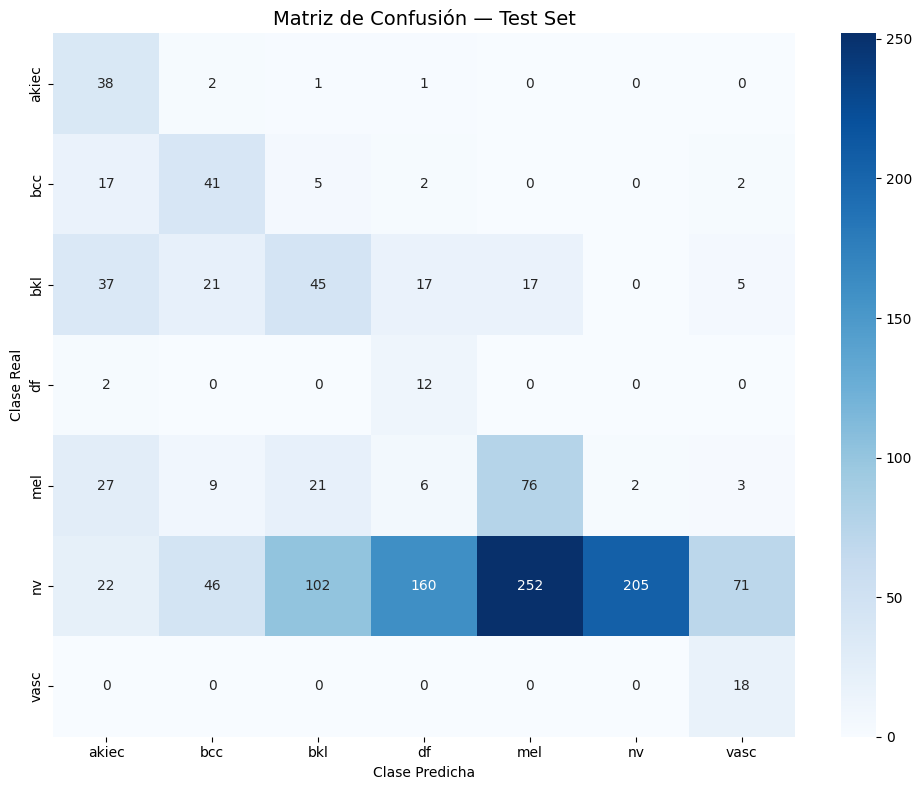

In [ ]:
# Matriz de confusión
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True, fmt='d',
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    cmap='Blues'
)
plt.title('Matriz de Confusión — Test Set', fontsize=14)
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'confusion_matrix_v2.png'), dpi=150)
plt.show()

## 11 · Resumen de resultados

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

acc  = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, average='macro')
rec  = recall_score(y_true, y_pred, average='macro')
f1   = f1_score(y_true, y_pred, average='macro')

print('=' * 50)
print('RESUMEN FINAL — DenseNet201 v2')
print('=' * 50)
print(f'  Accuracy  : {acc*100:.2f}%')
print(f'  Precision : {prec*100:.2f}% (macro)')
print(f'  Recall    : {rec*100:.2f}% (macro)')
print(f'  F1-score  : {f1*100:.2f}% (macro)')
print()
print(f'Mejores modelos guardados en:')
print(f'  {MODELS_DIR}/densenet201_v2_phase1_best.keras')
print(f'  {MODELS_DIR}/densenet201_v2_phase2_best.keras')

RESUMEN FINAL — DenseNet201 v2
  Accuracy  : 33.85%
  Precision : 33.17% (macro)
  Recall    : 63.68% (macro)
  F1-score  : 32.19% (macro)

Mejores modelos guardados en:
  /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v2_phase1_best.keras
  /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v2_phase2_best.keras
